# BABE Dataset — TF-IDF Baseline Comparison

Compare TF-IDF + Logistic Regression and TF-IDF + Linear SVM on the cleaned BABE binary classification dataset.

**Input columns:** `text`, `label_bias`, `news_link`, `outlet`.

- `text` is the model input.
- `label_bias` is the target (`Non-biased` / `Biased`).
- `news_link` and `outlet` are used only to create group-based evaluation splits, not as text features.
- This notebook reports random, article-link-disjoint, and outlet-disjoint results. Use the same exact split as RoBERTa for a direct comparison when those saved indices are available.

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
LABEL_ORDER = [0, 1]
LABEL_NAMES = ["Non-biased", "Biased"]

pd.set_option("display.max_columns", None)

## 1. Load and validate the cleaned dataset

Set `DATA_PATH` to the actual location of `babe_cleaned.csv`. If the CSV is in the same directory as this notebook, the default below works.

In [13]:
DATA_PATH = Path("babe_cleaned.csv")
if not DATA_PATH.exists():
    # Common alternative when notebook is stored in a notebooks/ folder
    DATA_PATH = Path("../data/processed/babe_cleaned.csv")

df = pd.read_csv(DATA_PATH)

required = {"text", "label_bias", "news_link", "outlet"}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
print("\nOriginal label counts:")
print(df["label_bias"].value_counts(dropna=False))

Dataset shape: (3669, 8)
Columns: ['text', 'news_link', 'outlet', 'topic', 'type', 'label_bias', 'label_opinion', 'biased_words']

Original label counts:
label_bias
Non-biased    1862
Biased        1807
Name: count, dtype: int64


In [14]:
# Clean only rows required for classification.
df = df.dropna(subset=["text", "label_bias"]).copy()
df["text"] = df["text"].astype(str).str.strip()
df = df[df["text"].ne("")].copy()
S
# Normalize labels and exclude any non-binary/ambiguous labels.
label_map = {
    "non-biased": 0,
    "biased": 1,
}
df["label_normalized"] = (
    df["label_bias"].astype(str).str.strip().str.lower()
)
df = df[df["label_normalized"].isin(label_map)].copy()
df["label"] = df["label_normalized"].map(label_map).astype(int)

# Check conflicting duplicate texts before deduplication.
conflicting_texts = (
    df.groupby("text")["label"].nunique().gt(1)
)
conflict_count = int(conflicting_texts.sum())
print("Unique texts with conflicting labels:", conflict_count)

# Exclude conflicting text entries rather than choosing an arbitrary label.
conflict_text_values = conflicting_texts[conflicting_texts].index
df = df[~df["text"].isin(conflict_text_values)].copy()

# Exact duplicate text rows now have consistent labels; keep one.
df = df.drop_duplicates(subset=["text"]).reset_index(drop=True)

print("\nCleaned dataset shape:", df.shape)
print("\nFinal class counts:")
print(df["label"].map({0: "Non-biased", 1: "Biased"}).value_counts())
print("\nClass proportions:")
print(df["label"].value_counts(normalize=True).sort_index().round(3))

Unique texts with conflicting labels: 0

Cleaned dataset shape: (3669, 10)

Final class counts:
label
Non-biased    1862
Biased        1807
Name: count, dtype: int64

Class proportions:
label
0    0.507
1    0.493
Name: proportion, dtype: float64


## 2. Prepare split groups

`news_link` helps keep the same linked article out of both train and test. Missing links get unique groups so unrelated rows are not accidentally grouped together. The outlet-disjoint split tests performance on publishers unseen during training.

In [15]:
X = df["text"].reset_index(drop=True)
y = df["label"].reset_index(drop=True)

# Unique fallback group for each row with a missing link.
links = df["news_link"].fillna("").astype(str).str.strip().reset_index(drop=True)
article_groups = links.copy()
missing_link = article_groups.eq("")
article_groups.loc[missing_link] = [
    f"missing_link_row_{i}" for i in article_groups.index[missing_link]
]

outlet_groups = (
    df["outlet"].fillna("Unknown").astype(str).str.strip()
    .replace("", "Unknown").reset_index(drop=True)
)

print("Samples:", len(X))
print("Unique article-link groups:", article_groups.nunique())
print("Unique outlets:", outlet_groups.nunique())

Samples: 3669
Unique article-link groups: 2127
Unique outlets: 11


## 3. Create three evaluation splits

These are separate evaluations, not three interchangeable estimates. Random split is a familiar baseline; article-link-disjoint and outlet-disjoint splits test stricter generalization.

For an exact comparison with RoBERTa, replace these splits with the same saved train/test row indices used by its final evaluation.

In [16]:
# Random, stratified split
idx = np.arange(len(df))
idx_train_random, idx_test_random = train_test_split(
    idx, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

# Article-link-disjoint split
article_splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.20, random_state=RANDOM_STATE
)
idx_train_article, idx_test_article = next(
    article_splitter.split(X, y, groups=article_groups)
)

# Outlet-disjoint split
outlet_splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.20, random_state=RANDOM_STATE
)
idx_train_outlet, idx_test_outlet = next(
    outlet_splitter.split(X, y, groups=outlet_groups)
)

split_indices = {
    "Random": (idx_train_random, idx_test_random),
    "Article-link-disjoint": (idx_train_article, idx_test_article),
    "Outlet-disjoint": (idx_train_outlet, idx_test_outlet),
}

split_data = {}
for split_name, (train_idx, test_idx) in split_indices.items():
    split_data[split_name] = (
        X.iloc[train_idx], X.iloc[test_idx],
        y.iloc[train_idx], y.iloc[test_idx]
    )
    print(f"\n{split_name}")
    print("Train:", len(train_idx), "| Test:", len(test_idx))
    print("Test class distribution:")
    print(y.iloc[test_idx].map({0: "Non-biased", 1: "Biased"}).value_counts())

# Verify group separation for grouped splits.
assert set(article_groups.iloc[idx_train_article]).isdisjoint(
    set(article_groups.iloc[idx_test_article])
)
assert set(outlet_groups.iloc[idx_train_outlet]).isdisjoint(
    set(outlet_groups.iloc[idx_test_outlet])
)


Random
Train: 2935 | Test: 734
Test class distribution:
label
Non-biased    373
Biased        361
Name: count, dtype: int64

Article-link-disjoint
Train: 2961 | Test: 708
Test class distribution:
label
Non-biased    372
Biased        336
Name: count, dtype: int64

Outlet-disjoint
Train: 1894 | Test: 1775
Test class distribution:
label
Non-biased    1052
Biased         723
Name: count, dtype: int64


## 4. Define TF-IDF baselines

Both models use the same TF-IDF features for a fair model comparison. `class_weight="balanced"` is included as a reasonable experiment; if you want to reproduce an earlier baseline exactly, use its original settings too.

In [17]:
def build_logistic_regression():
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2,
            max_features=100_000,
            sublinear_tf=True,
            strip_accents="unicode"
        )),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ])

def build_linear_svm():
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2,
            max_features=100_000,
            sublinear_tf=True,
            strip_accents="unicode"
        )),
        ("classifier", LinearSVC(
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ])

## 5. Train and evaluate

Report accuracy, macro-F1, macro-precision, and macro-recall. Macro-F1 is important because it weights the two classes equally.


=============== TF-IDF + Logistic Regression | Random ===============
              precision    recall  f1-score   support

  Non-biased     0.7551    0.6944    0.7235       373
      Biased     0.7084    0.7673    0.7367       361

    accuracy                         0.7302       734
   macro avg     0.7318    0.7308    0.7301       734
weighted avg     0.7322    0.7302    0.7300       734



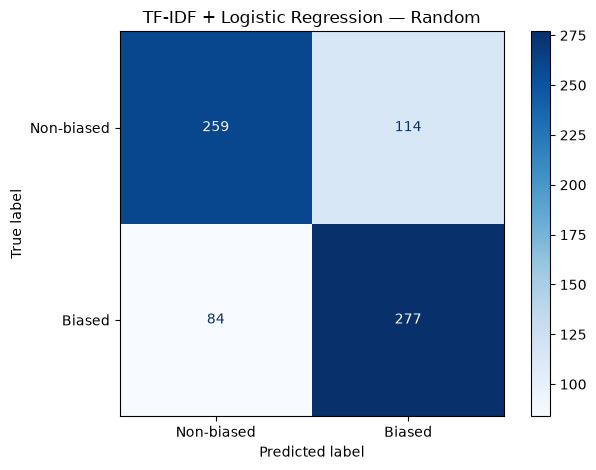


=============== TF-IDF + Linear SVM | Random ===============
              precision    recall  f1-score   support

  Non-biased     0.7384    0.6810    0.7085       373
      Biased     0.6949    0.7507    0.7217       361

    accuracy                         0.7153       734
   macro avg     0.7166    0.7158    0.7151       734
weighted avg     0.7170    0.7153    0.7150       734



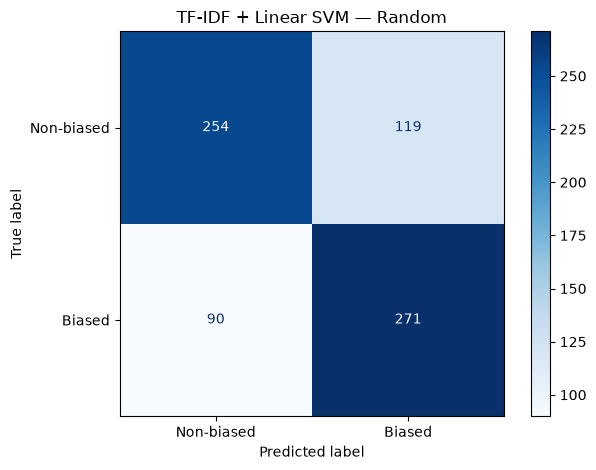


=============== TF-IDF + Logistic Regression | Article-link-disjoint ===============
              precision    recall  f1-score   support

  Non-biased     0.7493    0.6989    0.7232       372
      Biased     0.6898    0.7411    0.7145       336

    accuracy                         0.7189       708
   macro avg     0.7195    0.7200    0.7189       708
weighted avg     0.7210    0.7189    0.7191       708



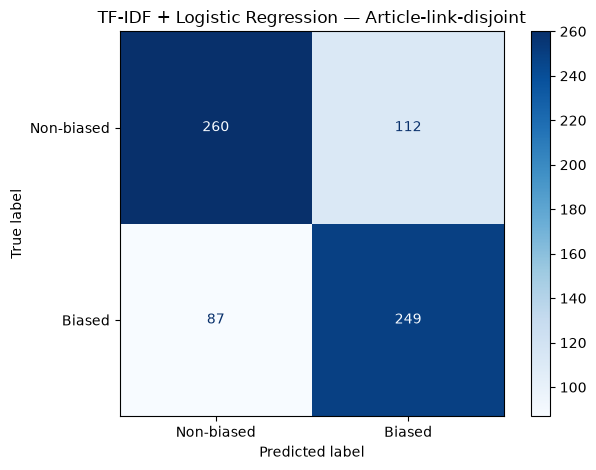


=============== TF-IDF + Linear SVM | Article-link-disjoint ===============
              precision    recall  f1-score   support

  Non-biased     0.7464    0.7043    0.7248       372
      Biased     0.6919    0.7351    0.7128       336

    accuracy                         0.7189       708
   macro avg     0.7192    0.7197    0.7188       708
weighted avg     0.7205    0.7189    0.7191       708



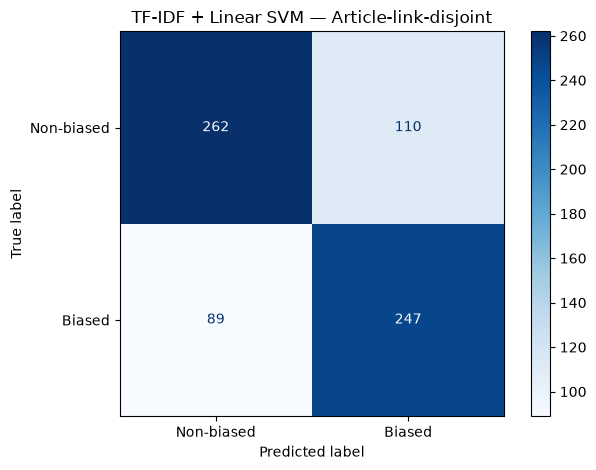


=============== TF-IDF + Logistic Regression | Outlet-disjoint ===============
              precision    recall  f1-score   support

  Non-biased     0.7537    0.7300    0.7417      1052
      Biased     0.6243    0.6528    0.6383       723

    accuracy                         0.6986      1775
   macro avg     0.6890    0.6914    0.6900      1775
weighted avg     0.7010    0.6986    0.6996      1775



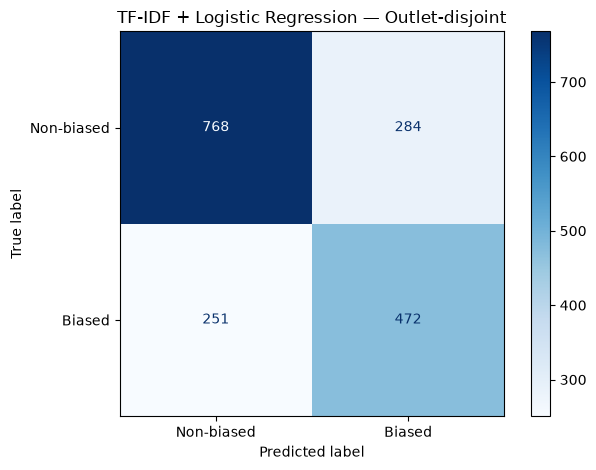


=============== TF-IDF + Linear SVM | Outlet-disjoint ===============
              precision    recall  f1-score   support

  Non-biased     0.7479    0.6854    0.7153      1052
      Biased     0.5919    0.6639    0.6258       723

    accuracy                         0.6766      1775
   macro avg     0.6699    0.6746    0.6705      1775
weighted avg     0.6844    0.6766    0.6788      1775



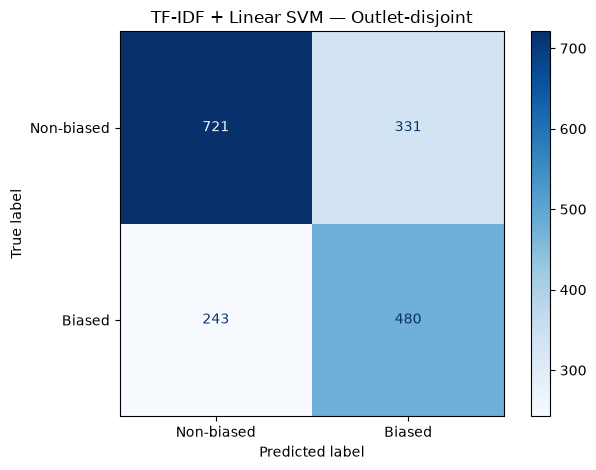

In [20]:
def evaluate_model(model, X_train, y_train, X_test, y_test,
                   model_name, split_name):
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    result = {
        "Model": model_name,
        "Split": split_name,
        "Train size": len(X_train),
        "Test size": len(X_test),
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro-F1": f1_score(
            y_test, predictions, labels=LABEL_ORDER,
            average="macro", zero_division=0
        ),
        "Macro-Precision": precision_score(
            y_test, predictions, labels=LABEL_ORDER,
            average="macro", zero_division=0
        ),
        "Macro-Recall": recall_score(
            y_test, predictions, labels=LABEL_ORDER,
            average="macro", zero_division=0
        )
    }

    print(f"\n{'=' * 15} {model_name} | {split_name} {'=' * 15}")
    print(classification_report(
        y_test, predictions,
        labels=LABEL_ORDER, target_names=LABEL_NAMES,
        digits=4, zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions,
        labels=LABEL_ORDER, display_labels=LABEL_NAMES,
        cmap="Blues", values_format="d"
    )
    plt.title(f"{model_name} — {split_name}")
    plt.tight_layout()
    plt.show()

    return result, model

model_builders = {
    "TF-IDF + Logistic Regression": build_logistic_regression,
    "TF-IDF + Linear SVM": build_linear_svm,
}

all_results = []
trained_models = {}

for split_name, (Xtr, Xte, ytr, yte) in split_data.items():
    for model_name, builder in model_builders.items():
        result, trained_model = evaluate_model(
            builder(), Xtr, ytr, Xte, yte, model_name, split_name
        )
        all_results.append(result)
        trained_models[(model_name, split_name)] = trained_model

## 6. Compare and save results

,Model,Split,Train size,Test size,Accuracy,Macro-F1,Macro-Precision,Macro-Recall
0,TF-IDF + Logistic Regression,Article-link-disjoint,2961,708,0.7189,0.7189,0.7195,0.7200
1,TF-IDF + Linear SVM,Article-link-disjoint,2961,708,0.7189,0.7188,0.7192,0.7197
2,TF-IDF + Logistic Regression,Outlet-disjoint,1894,1775,0.6986,0.6900,0.6890,0.6914
3,TF-IDF + Linear SVM,Outlet-disjoint,1894,1775,0.6766,0.6705,0.6699,0.6746
4,TF-IDF + Logistic Regression,Random,2935,734,0.7302,0.7301,0.7318,0.7308
5,TF-IDF + Linear SVM,Random,2935,734,0.7153,0.7151,0.7166,0.7158


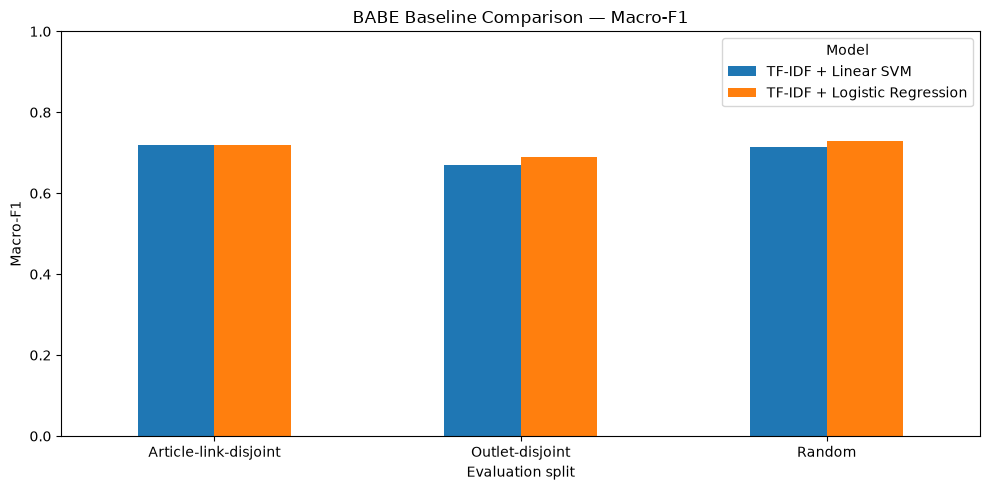

Saved results to: C:\Users\ADMIN\Desktop\News Bias Detection\news-bias-detection\notebooks\results\babe_baseline_comparison.csv


In [19]:
results_df = pd.DataFrame(all_results).sort_values(
    ["Split", "Macro-F1"], ascending=[True, False]
).reset_index(drop=True)

display(results_df.round(4))

ax = results_df.pivot(
    index="Split", columns="Model", values="Macro-F1"
).plot(kind="bar", figsize=(10, 5), ylim=(0, 1), rot=0)

ax.set_title("BABE Baseline Comparison — Macro-F1")
ax.set_ylabel("Macro-F1")
ax.set_xlabel("Evaluation split")
plt.tight_layout()
plt.show()

OUTPUT_DIR = Path("results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
results_path = OUTPUT_DIR / "babe_baseline_comparison.csv"
results_df.to_csv(results_path, index=False)
print("Saved results to:", results_path.resolve())

## Interpretation notes

- Use the **same exact held-out test examples** to compare TF-IDF against RoBERTa directly.
- Random split can be easier than article-link- or outlet-disjoint evaluation.
- Outlet-disjoint performance may vary substantially because whole outlets are held out and class balance may shift.
- Do not select hyperparameters using the test set. Tune on training data with cross-validation or a validation split, then evaluate once on the final test set.
- `news_link` and `outlet` are used for grouping only; neither is passed to the TF-IDF vectorizer.